/home/mateusz/miniconda3/envs/cirr/lib/python3.12/site-packages/cartopy/mpl/feature_artist.py:144: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


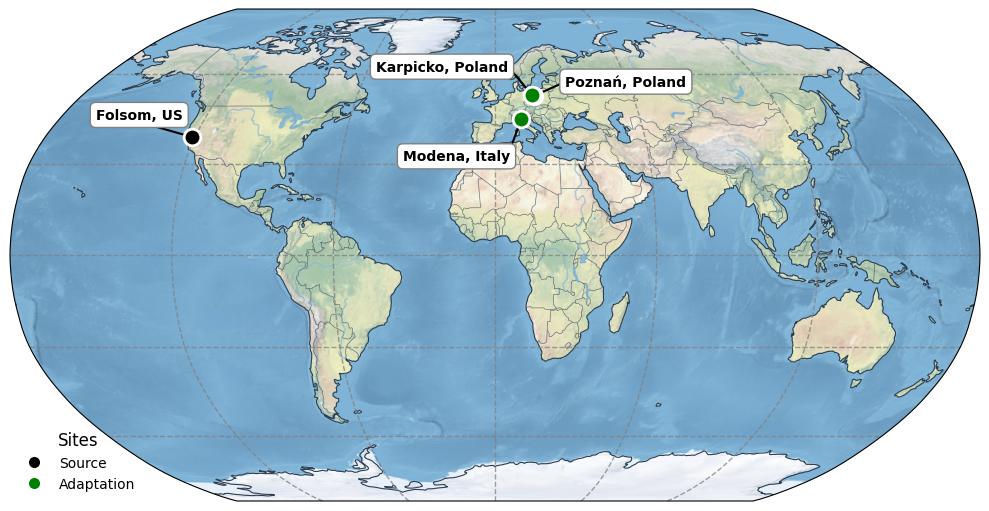

In [8]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Create figure with Robinson projection
fig = plt.figure(figsize=(10, 10))
ax = plt.axes(projection=ccrs.Robinson())

ax.stock_img()

# Add map features with terrain colors
ax.add_feature(cfeature.COASTLINE, linewidth=0.8, color='#2c3e50')
ax.add_feature(cfeature.BORDERS, linewidth=0.5, alpha=0.7, color='#34495e')
ax.add_feature(cfeature.OCEAN, color='#7fb3d3')  # Light blue ocean
ax.add_feature(cfeature.LAKES, color='#7fb3d3', alpha=0.8)
ax.add_feature(cfeature.RIVERS, color='#7fb3d3', alpha=0.6)

# Add different terrain colors to match the reference
ax.add_feature(cfeature.LAND)#, color='#f4e4bc')

# Set global extent for Robinson projection
ax.set_global()

# Add gridlines (Robinson projection handles gridlines differently)
gl = ax.gridlines(draw_labels=False, linewidth=1.0, color='gray', alpha=0.75, linestyle='--')
gl.top_labels = False
gl.right_labels = False

# Define locations with their coordinates, colors, and label positions
locations = [
    {'name': 'Folsom, US', 'lat': 38.6779, 'lon': -121.1760, 'color': 'black', 
     'label_offset': (-25, 5), 'ha': 'center', 'va': 'bottom'},
    {'name': 'Modena, Italy', 'lat': 44.6479, 'lon': 10.9252, 'color': 'green', 
     'label_offset': (-5, -10), 'ha': 'right', 'va': 'top'},
    {'name': 'Poznań, Poland', 'lat': 52.4064, 'lon': 16.9252, 'color': 'green', 
     'label_offset': (15, 5), 'ha': 'left', 'va': 'center'},
    {'name': 'Karpicko, Poland', 'lat': 52.7667, 'lon': 16.2333, 'color': 'green', 
     'label_offset': (-10, 10), 'ha': 'right', 'va': 'center'}
]

# Add pins to the map with larger size and connecting lines to labels
for location in locations:   
    # Calculate label position
    label_lon = location['lon'] + location['label_offset'][0]
    label_lat = location['lat'] + location['label_offset'][1]
    
    # Add connecting line from pin to label
    ax.plot([location['lon'], label_lon], [location['lat'], label_lat],
            color='black', linewidth=1.5, alpha=1.0,
            transform=ccrs.PlateCarree())
    
    # Add city labels at offset positions
    ax.text(label_lon, label_lat, 
            location['name'], 
            fontsize=10, 
            ha=location['ha'],
            va=location['va'],
            weight='bold',
            transform=ccrs.PlateCarree(),
            bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=1.0, edgecolor='gray'))

    # Plot the pin (larger size)
    ax.plot(location['lon'], location['lat'], 
            marker='o', 
            markersize=12, 
            color=location['color'],
            markeredgecolor='white',
            markeredgewidth=2,
            transform=ccrs.PlateCarree())

# Add legend - black dot means source location, while green dots represents adaptation / deployment sites
legend_elements = [
    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor='black', markersize=10, markeredgecolor='white', markeredgewidth=2, label='Source'),
    plt.Line2D([0], [0], marker='o', color='w',
                markerfacecolor='green', markersize=10, markeredgecolor='white', markeredgewidth=2, label='Adaptation')
]
ax.legend(handles=legend_elements, loc='lower left', fontsize=10, frameon=False, title='Sites', title_fontsize='12', borderpad=0.25)


# Adjust layout and display
plt.tight_layout()
# plt.show()

# Optional: Save the map
plt.savefig('world_map_with_pins.png', dpi=300, bbox_inches='tight')